In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import joblib
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [51]:
file_path = "/kaggle/input/datasets/nourmohd/online-retail-ii-dataset/online_retail_II.xlsx"

dfs = pd.read_excel(file_path, sheet_name=["Year 2009-2010", "Year 2010-2011"])

df1 = dfs["Year 2009-2010"]
df2 = dfs["Year 2010-2011"]

In [2]:
# ---------------------------------------------------------
# 1. DATA LOADING & CONCATENATION
# ---------------------------------------------------------
print("Loading data...")
file_path = "/kaggle/input/datasets/nourmohd/online-retail-ii-dataset/online_retail_II.xlsx"
dfs = pd.read_excel(file_path, sheet_name=["Year 2009-2010", "Year 2010-2011"])

df1 = dfs["Year 2009-2010"]
df2 = dfs["Year 2010-2011"]

df = pd.concat([df1, df2], ignore_index=True)
print(f"Initial raw shape: {df.shape}")

# Standardize column names
df.columns = [col.strip().replace(" ", "_") for col in df.columns]

Loading data...
Initial raw shape: (1067371, 8)


In [7]:
# ---------------------------------------------------------
# 2. DATA CLEANING
# ---------------------------------------------------------
print("Cleaning data...")
# Remove rows without Customer ID
df = df.dropna(subset=['Customer_ID'])
df['Customer_ID'] = df['Customer_ID'].astype(int)

# Filter out cancellations (Invoices starting with 'C') and non-positive quantities/prices
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Calculate Total Spend per transaction
df['Total_Spend'] = df['Quantity'] * df['Price']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Cleaned shape: {df.shape}")

Cleaning data...


/tmp/ipykernel_49/783288895.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Customer_ID'] = df['Customer_ID'].astype(int)


Cleaned shape: (805549, 9)


/tmp/ipykernel_49/4089857329.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette="viridis")


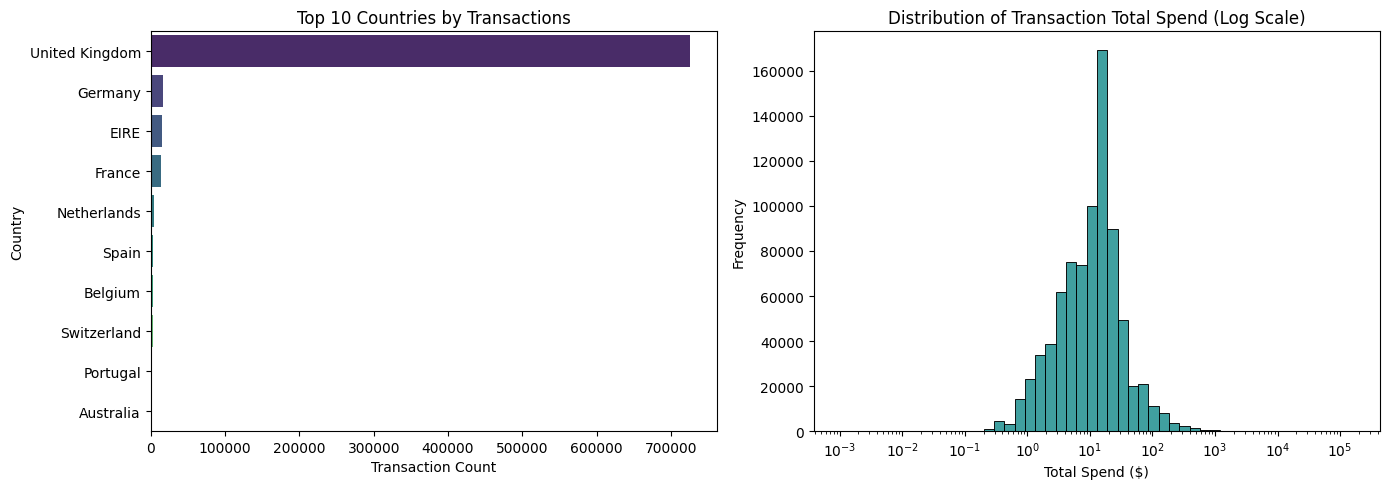

In [12]:
# ---------------------------------------------------------
# EDA VISUALS: Data Distribution & Top Products/Countries
# ---------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot 1: Top 10 Countries by Transaction Count
plt.subplot(1, 2, 1)
top_countries = df['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette="viridis")
plt.title("Top 10 Countries by Transactions")
plt.xlabel("Transaction Count")

# Plot 2: Distribution of Total Spend per Transaction (Log scale due to skew)
plt.subplot(1, 2, 2)
sns.histplot(df['Total_Spend'], bins=50, color='teal', log_scale=True)
plt.title("Distribution of Transaction Total Spend (Log Scale)")
plt.xlabel("Total Spend ($)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("eda_overview_plots.png") # Saves the plot locally
plt.show()

In [8]:
# ---------------------------------------------------------
# 3. TIME CUT-OFF & FEATURE CREATION (NO LEAKAGE)
# ---------------------------------------------------------
# Maximizing observation range: Cut-off date is set 90 days before max date
max_date = df['InvoiceDate'].max()
cutoff_date = max_date - pd.Timedelta(days=90)

print(f"Max Date in Dataset: {max_date}")
print(f"Observation Cut-off Date: {cutoff_date}")

# Split features window vs. target window
obs_df = df[df['InvoiceDate'] <= cutoff_date]
target_df = df[df['InvoiceDate'] > cutoff_date]

# Calculate RFM Features (Observation Window)
rfm = obs_df.groupby('Customer_ID').agg({
    'InvoiceDate': lambda x: (cutoff_date - x.max()).days, # Recency
    'Invoice': 'nunique',                                  # Frequency
    'Total_Spend': 'sum'                                   # Monetary Value
}).reset_index()

rfm.columns = ['Customer_ID', 'Recency', 'Frequency', 'Monetary']

# Calculate Target (Target Window: Next 90 Days Spend)
target_spend = target_df.groupby('Customer_ID')['Total_Spend'].sum().reset_index()
target_spend.columns = ['Customer_ID', 'Target_90D_Spend']

# Merge RFM + Target
dataset = pd.merge(rfm, target_spend, on='Customer_ID', how='left')
dataset['Target_90D_Spend'] = dataset['Target_90D_Spend'].fillna(0.0)

Max Date in Dataset: 2011-12-09 12:50:00
Observation Cut-off Date: 2011-09-10 12:50:00


In [9]:
# ---------------------------------------------------------
# 4. CUSTOMER SEGMENTATION (UNSUPERVISED)
# ---------------------------------------------------------
print("Training Clustering Model...")
X_rfm = dataset[['Recency', 'Frequency', 'Monetary']]

# Log transform to reduce skewness
X_rfm_log = np.log1p(X_rfm)

# Standard Scaler
scaler_rfm = StandardScaler()
X_rfm_scaled = scaler_rfm.fit_transform(X_rfm_log)

# K-Means Clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
dataset['Cluster'] = kmeans.fit_predict(X_rfm_scaled)

# PCA for Visual Dimensions
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_rfm_scaled)
dataset['PCA1'] = pca_coords[:, 0]
dataset['PCA2'] = pca_coords[:, 1]

# Segment Profiling & Naming
cluster_summary = dataset.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Customer_ID': 'count'
}).rename(columns={'Customer_ID': 'Count'})

print("\n--- Cluster Summary ---")
print(cluster_summary)

# Assign Human-readable Segment Names based on characteristics
def name_segment(row):
    if row['Cluster'] == 0:
        return 'At-Risk / Lost'
    elif row['Cluster'] == 1:
        return 'Recent / New'
    elif row['Cluster'] == 2:
        return 'Champions / VIP'
    else:
        return 'Loyal Moderate'

dataset['Segment_Name'] = dataset.apply(name_segment, axis=1)

# Map Recommended Actions
action_map = {
    'Champions / VIP': 'Exclusive VIP loyalty rewards, early product launches, priority support.',
    'Loyal Moderate': 'Upsell bundled products, cross-category recommendations, loyalty tiers.',
    'Recent / New': 'Welcome onboarding email series, first-time purchase incentives.',
    'At-Risk / Lost': 'Win-back campaigns, targeted discount offers, feedback surveys.'
}
dataset['Recommended_Action'] = dataset['Segment_Name'].map(action_map)

Training Clustering Model...

--- Cluster Summary ---
            Recency  Frequency      Monetary  Count
Cluster                                            
0        197.187539   5.158879   2067.730856   1605
1        344.114097   1.420085    351.505512   2121
2         30.378499  19.333707  10898.159091    893
3         31.995468   2.697885    741.844671    662


/tmp/ipykernel_49/1035410568.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_counts.index, y=segment_counts.values, palette="magma")
/tmp/ipykernel_49/1035410568.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Segment_Name', y='Monetary', data=segment_monetary, palette="magma")


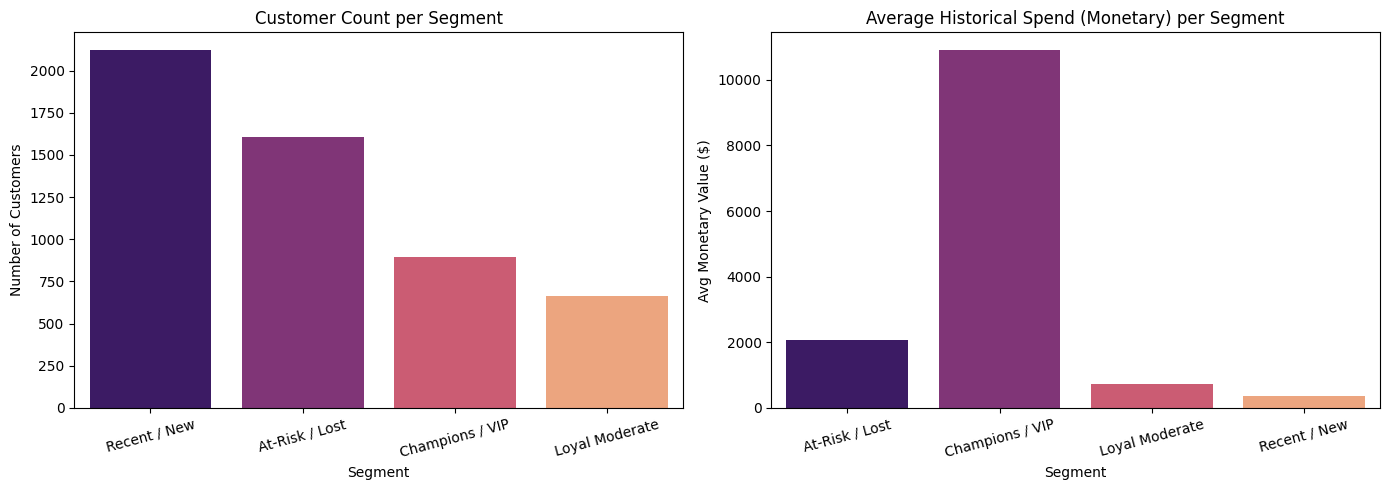

In [13]:
# ---------------------------------------------------------
# CLUSTERING VISUALS: RFM Segment Profiles & Counts
# ---------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot 1: Segment Customer Counts
plt.subplot(1, 2, 1)
segment_counts = dataset['Segment_Name'].value_counts()
sns.barplot(x=segment_counts.index, y=segment_counts.values, palette="magma")
plt.title("Customer Count per Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

# Plot 2: Average Monetary Spend per Segment
plt.subplot(1, 2, 2)
segment_monetary = dataset.groupby('Segment_Name')['Monetary'].mean().reset_index()
sns.barplot(x='Segment_Name', y='Monetary', data=segment_monetary, palette="magma")
plt.title("Average Historical Spend (Monetary) per Segment")
plt.xlabel("Segment")
plt.ylabel("Avg Monetary Value ($)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("segmentation_profiles.png")
plt.show()

In [10]:
# ---------------------------------------------------------
# 5. REGRESSION MODEL (SUPERVISED CLV PREDICTION)
# ---------------------------------------------------------
print("Training Regression Model for 90-Day CLV...")
feature_cols = ['Recency', 'Frequency', 'Monetary', 'Cluster']
X = dataset[feature_cols]
y = dataset['Target_90D_Spend']

# Fit Regressor
regressor = RandomForestRegressor(n_estimators=100, random_state=42)
regressor.fit(X, y)

# Predict & Evaluate
dataset['Predicted_90D_Spend'] = regressor.predict(X)
dataset['Predicted_90D_Spend'] = dataset['Predicted_90D_Spend'].clip(lower=0)

rmse = np.sqrt(mean_squared_error(y, dataset['Predicted_90D_Spend']))
mae = mean_absolute_error(y, dataset['Predicted_90D_Spend'])
r2 = r2_score(y, dataset['Predicted_90D_Spend'])

print(f"\n--- Model Performance ---")
print(f"RMSE: ${rmse:.2f}")
print(f"MAE:  ${mae:.2f}")
print(f"R²:   {r2:.4f}")

Training Regression Model for 90-Day CLV...

--- Model Performance ---
RMSE: $1241.95
MAE:  $195.72
R²:   0.9046


/tmp/ipykernel_49/598134811.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_importance_df, palette="coolwarm")


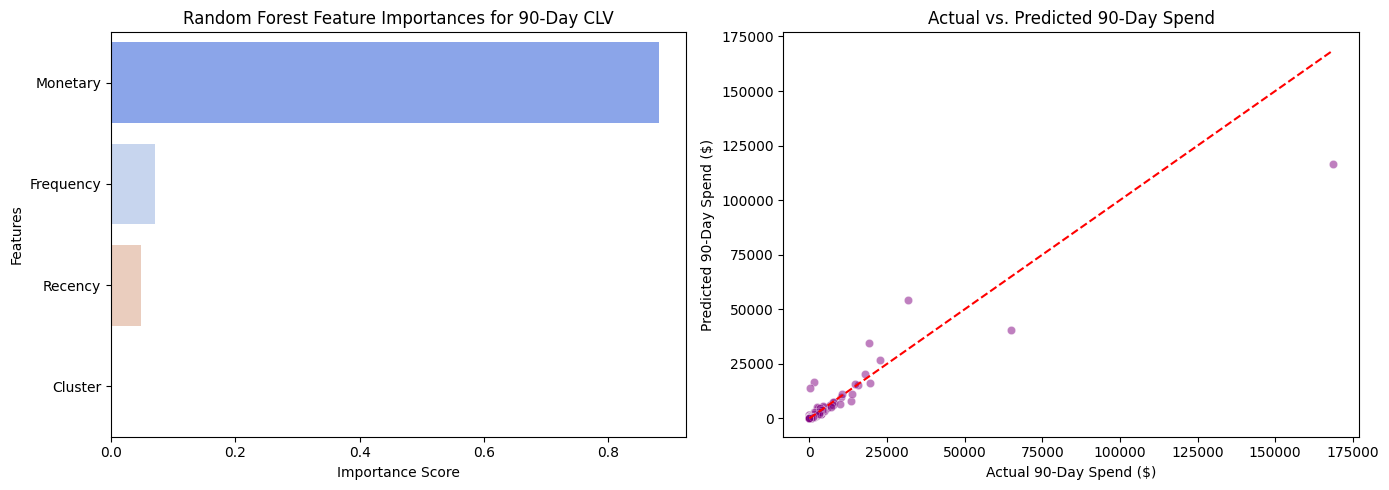

In [14]:
# ---------------------------------------------------------
# REGRESSION VISUALS: Feature Importances & Actual vs Predicted
# ---------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot 1: Feature Importances from Random Forest
plt.subplot(1, 2, 1)
importances = regressor.feature_importances_
feat_importance_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances})
feat_importance_df = feat_importance_df.sort_values(by='Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=feat_importance_df, palette="coolwarm")
plt.title("Random Forest Feature Importances for 90-Day CLV")
plt.xlabel("Importance Score")
plt.ylabel("Features")

# Plot 2: Actual vs Predicted Spend (Sampled for clean visualization)
plt.subplot(1, 2, 2)
eval_subset = dataset[['Target_90D_Spend', 'Predicted_90D_Spend']].sample(n=min(2000, len(dataset)), random_state=42)
sns.scatterplot(x='Target_90D_Spend', y='Predicted_90D_Spend', data=eval_subset, alpha=0.5, color='purple')
plt.plot([0, eval_subset['Target_90D_Spend'].max()], [0, eval_subset['Target_90D_Spend'].max()], color='red', linestyle='--')
plt.title("Actual vs. Predicted 90-Day Spend")
plt.xlabel("Actual 90-Day Spend ($)")
plt.ylabel("Predicted 90-Day Spend ($)")

plt.tight_layout()
plt.savefig("regression_evaluation.png")
plt.show()

In [11]:
# ---------------------------------------------------------
# 6. SAVE ARTIFACTS
# ---------------------------------------------------------
artifacts = {
    'scaler_rfm': scaler_rfm,
    'kmeans': kmeans,
    'pca': pca,
    'regressor': regressor,
    'dataset': dataset,
    'cutoff_date': cutoff_date
}

joblib.dump(artifacts, 'clv_segmentation_artifacts.pkl')
print("\nAll artifacts and processed dataset saved to 'clv_segmentation_artifacts.pkl'!")


All artifacts and processed dataset saved to 'clv_segmentation_artifacts.pkl'!
